# Thresholding

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### simple thresholding

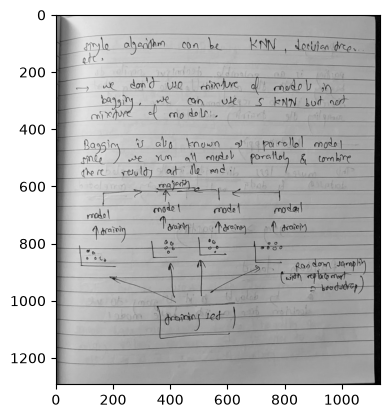

In [2]:
img = cv2.imread('./data/handwritten.jpeg', 0)
plt.imshow(img, 'grey')

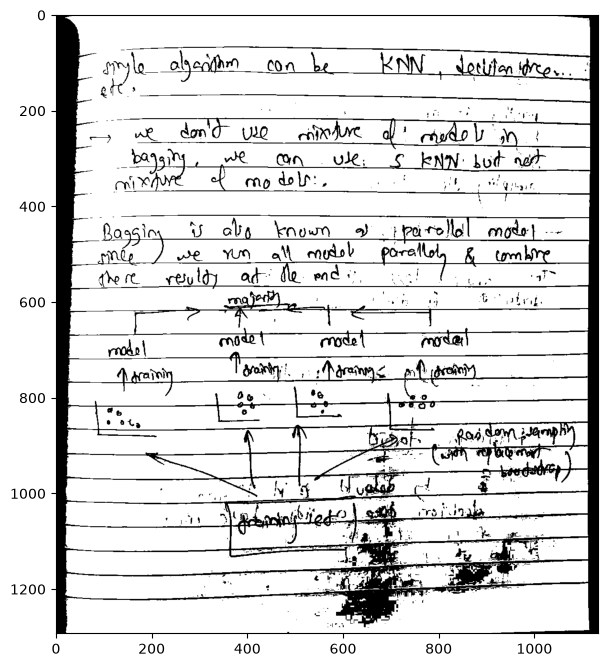

In [ ]:
retval, binary_msk = cv2.threshold(src=img, thresh=150, maxval=255, type=cv2.THRESH_BINARY)
'''
255 if pixel > 150, else 0
'''
plt.figure(figsize=(7,12))
plt.imshow(binary_msk, 'grey')

### Adaptive thresholding

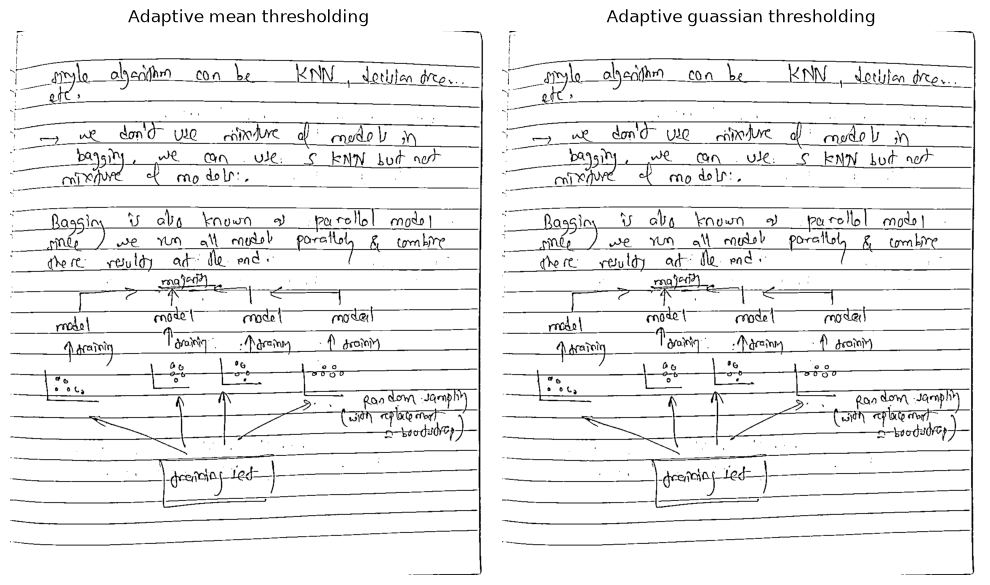

In [12]:
adapt_mean = cv2.adaptiveThreshold(src=img, # Input 8-bit single-channel (grayscale) image
                                   maxValue=255, # Output value assigned to pixels classified as foreground
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C, # Calculate the local threshold using the neighborhood mean
                                   thresholdType=cv2.THRESH_BINARY, # Pixels above the local threshold become 255; others become 0
                                   blockSize=11,  # Size of the local neighborhood (11 × 11 pixels); must be an odd integer greater than 1
                                   C=25) # Constant subtracted from the calculated local threshold

adapt_gaus = cv2.adaptiveThreshold(src=img, # Input 8-bit single-channel (grayscale) image
                                   maxValue=255, # Output value assigned to pixels classified as foreground
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C, # Calculate the local threshold using a Gaussian-weighted sum of neighborhood pixels
                                   thresholdType=cv2.THRESH_BINARY, # Pixels above the local threshold become 255; others become 0
                                   blockSize=11,  # Size of the local neighborhood (11 × 11 pixels); must be an odd integer greater than 1
                                   C=25) # Constant subtracted from the calculated local threshold


plt.figure(figsize=(10, 24))

plt.subplot(1,2,1)
plt.imshow(adapt_mean, cmap='grey')
plt.title("Adaptive mean thresholding")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(adapt_gaus, cmap='grey')
plt.title("Adaptive guassian thresholding")
plt.axis('off')

plt.tight_layout()
plt.show()

# kmeans clustering

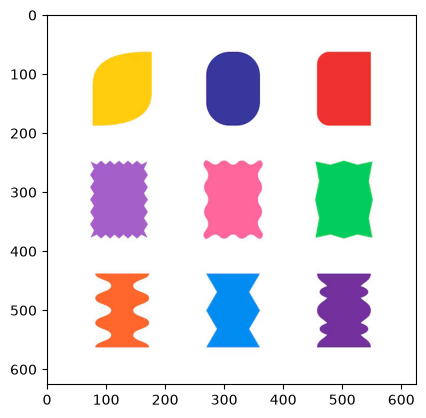

In [13]:
img = cv2.imread('./data/shapes.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [ ]:
print(img.shape) # 3-dimension data

(626, 626, 3)
3


(None, None)

In [ ]:
# Prepare data for kmeans clustering algorithm
pixel_val = img.reshape((-1,3)).astype(np.float32) # suitable data type for OpenCV's K-Means implementation
print(pixel_val.shape) # 2-dimension data

(391876, 3)


In [20]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
'''
NOTE: Define the termination criteria for the K-Means algorithm. As per documentation:

--> criteria = (type, maxCount, epsilon)

cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER
--> Stop when either the required accuracy is reached or the maximum number of iterations is reached

100
--> Maximum number of iterations allowed

0.2
--> Epsilon: Stop if the cluster centers change by less than this threshold

'''

k = 3 # number of clusters

_, labels, centers = cv2.kmeans(data=pixel_val, # pixel color values, typically shaped (number_of_pixels, 3) and converted to float32
                                K=k, # number of clusters to create
                                bestLabels=None, # no initial cluster assignments are provided; OpenCV initializes them based on the selected flags
                                criteria=criteria, # termination criteria controlling when the algorithm stops
                                attempts=10, # run the algorithm 10 times with different initial cluster centers and retain the best result
                                flags=cv2.KMEANS_RANDOM_CENTERS) # initialize cluster centers randomly

In [ ]:
print(labels.shape)
print(centers) # 3 clusters with XYZ values

(391876, 1)
[[ 70.9147   110.96521  167.68669 ]
 [255.2777   255.2192   255.20657 ]
 [249.43346  114.88152   69.147255]]


In [29]:
np.unique(labels.flatten(), return_counts=True)

(array([0, 1, 2], dtype=int32), array([ 51279, 299214,  41383]))

[[ 70 110 167]
 [255 255 255]
 [249 114  69]]


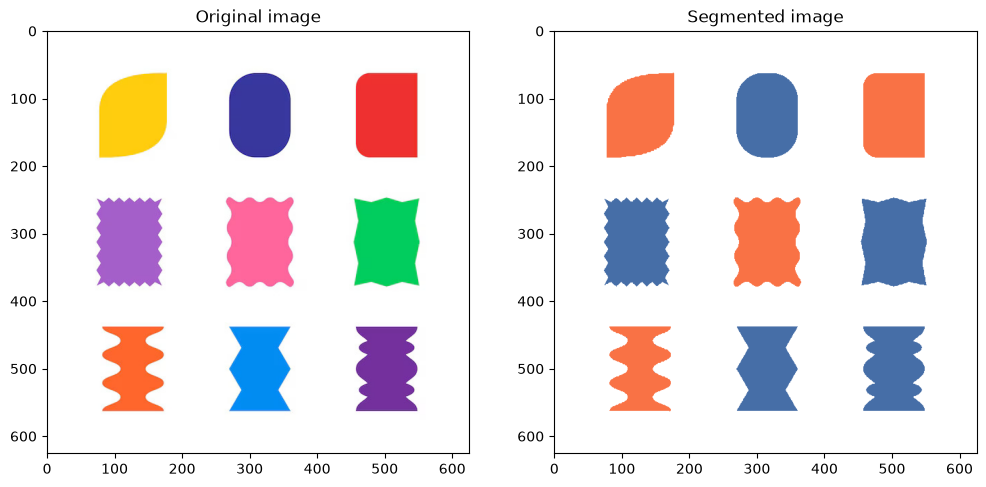

In [ ]:
# Reconstruct the image
centers = np.uint8(centers) # convert to 8-bit unsigned integer
segmented_img = centers[labels.flatten()].reshape(img.shape)

# Label indexing
# 0 --> [70,110, 167]
# 1 --> [255, 255, 255]
# 2 --> [249 114  69]

plt.figure(figsize=(12,7))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original image")

plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title("Segmented image")

plt.show()

In the image, only can see 2 categories. The remaining one is the whole image itself.

# watershed algorithm

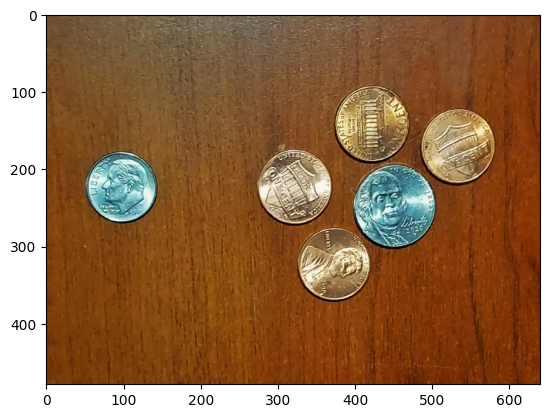

In [25]:
image = cv2.imread("../images/coin2.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
original_image = image.copy()
plt.imshow(image)

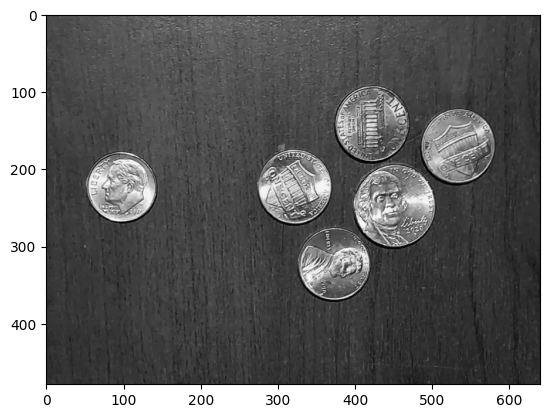

In [26]:
grey = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(grey, cmap='grey')

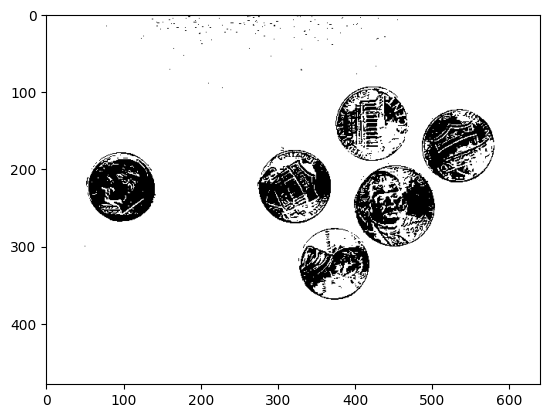

In [29]:
_, thresh = cv2.threshold(grey, 130, 255, cv2.THRESH_BINARY_INV)
plt.imshow(thresh,cmap='grey')

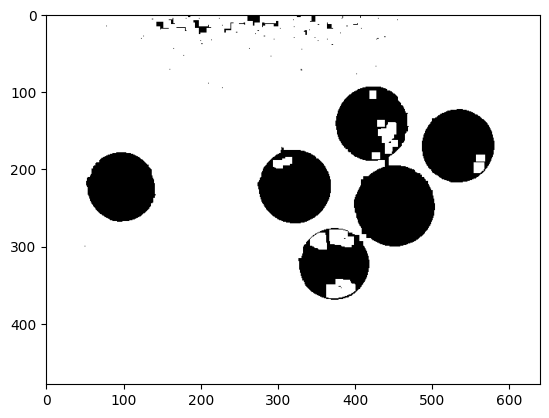

In [33]:
kernel = np.ones((3,3), np.uint8)
opeaning = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=4)

plt.imshow(opeaning, cmap='grey')

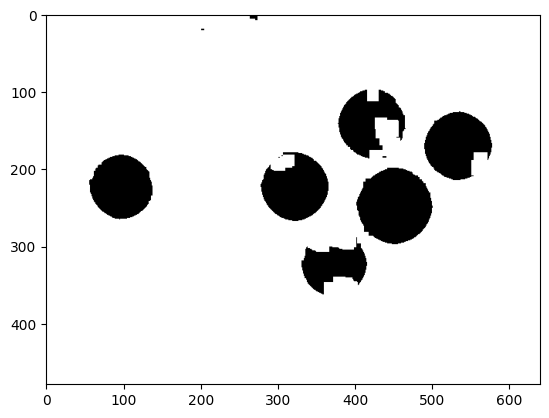

In [34]:
sure_bg = cv2.dilate(opeaning, kernel, iterations=3)
plt.imshow(sure_bg, cmap='grey')

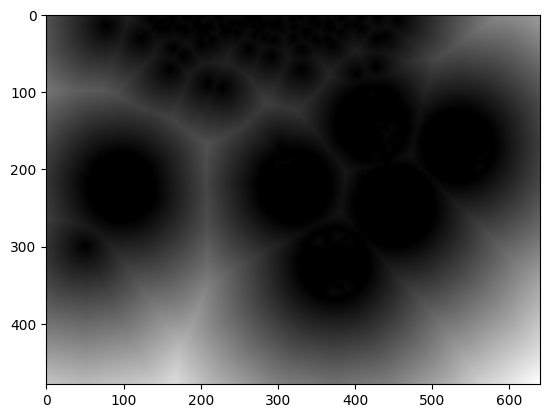

In [36]:
dist_transform = cv2.distanceTransform(opeaning, cv2.DIST_L2, 5)

plt.imshow(dist_transform, cmap='grey')

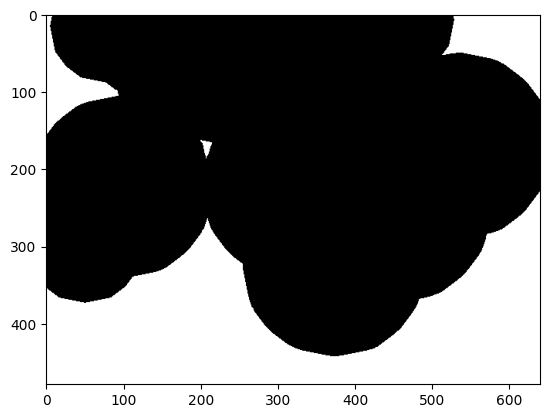

In [40]:
_, sure_fg = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)

sure_fg = np.uint8(sure_fg)

plt.imshow(sure_fg, cmap='grey')

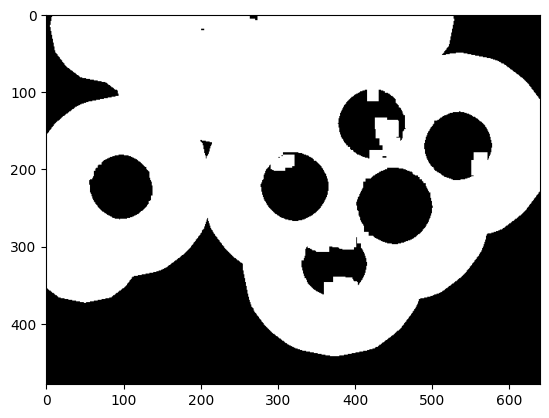

In [41]:
unknown = cv2.subtract(sure_bg, sure_fg)
plt.imshow(unknown, cmap='grey')

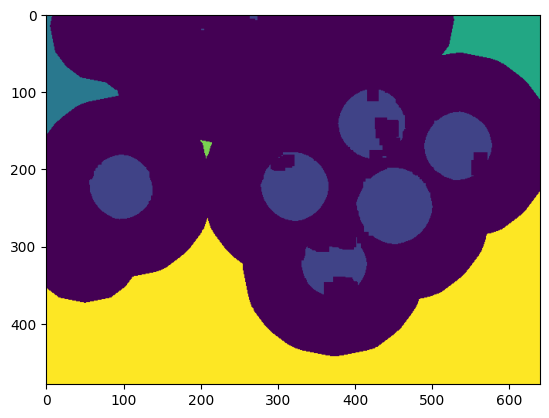

In [42]:
_, markers = cv2.connectedComponents(sure_fg)
markers = markers+1
markers[unknown== 255] = 0

plt.imshow(markers)

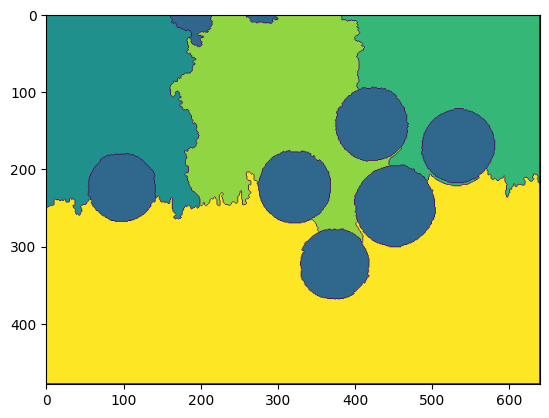

In [43]:
markers = cv2.watershed(image, markers)
plt.imshow(markers)

In [45]:
coin_mask = np.zeros_like(grey)

print(grey.shape)
print(coin_mask.shape)

unique_labels = np.unique(markers)

instance_number = 1
font = cv2.FONT_HERSHEY_SIMPLEX

for label in unique_labels:
    if label == 0 or label == -1:
        continue

    mask = np.uint8(markers == label)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for contour in contours:
        area = cv2.contourArea(contour)
        perimerter = cv2.arcLength(contour,True)

        if perimerter == 0:
            continue

        circularity = 4 * np.pi * (area / (perimerter * perimerter))

        if 0.7 < circularity < 1.2 and area > 1000:
            cv2.drawContours(original_image, [contour], -1, (0,255,0), 2)
            x, y, w, h = cv2.boundingRect(contour)
            cv2.putText(original_image, f'Coin {instance_number}', (x, y-10), font, 0.6, (255,0, 0), 2)
            coin_mask = cv2.bitwise_or(coin_mask, mask)
            cv2.rectangle(original_image,(x-5, y-5), (x+w+5, y+h+5), (160, 150, 250), 2)
            instance_number += 1


(479, 640)
(479, 640)


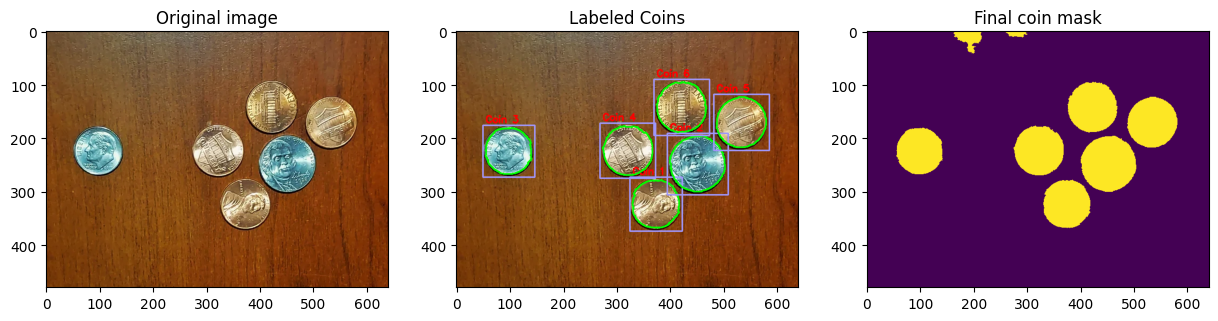

In [46]:
plt.figure(figsize=(15,10))


plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(original_image)
plt.title("Labeled Coins")

plt.subplot(1,3,3)
plt.imshow(coin_mask)
plt.title("Final coin mask")

plt.show()